In [2]:
import pandas as pd

df = pd.read_csv("../data/medquad.csv")
print(df.shape)
df.head()

(16412, 4)


,question,answer,source,focus_area
0,What is (are) Glaucoma ?,Glaucoma is a group of diseases that can damag...,NIHSeniorHealth,Glaucoma
1,What causes Glaucoma ?,"Nearly 2.7 million people have glaucoma, a lea...",NIHSeniorHealth,Glaucoma
2,What are the symptoms of Glaucoma ?,Symptoms of Glaucoma Glaucoma can develop in ...,NIHSeniorHealth,Glaucoma
3,What are the treatments for Glaucoma ?,"Although open-angle glaucoma cannot be cured, ...",NIHSeniorHealth,Glaucoma
4,What is (are) Glaucoma ?,Glaucoma is a group of diseases that can damag...,NIHSeniorHealth,Glaucoma


In [3]:
df.info()
print(df.isna().sum())
print("Doublons de réponses :", df["answer"].duplicated().sum())
print("Doublons de questions :", df["question"].duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 16412 entries, 0 to 16411
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   question    16412 non-null  str  
 1   answer      16407 non-null  str  
 2   source      16412 non-null  str  
 3   focus_area  16398 non-null  str  
dtypes: str(4)
memory usage: 513.0 KB
question       0
answer         5
source         0
focus_area    14
dtype: int64
Doublons de réponses : 594
Doublons de questions : 1428


In [4]:
print(df["source"].value_counts())

source
GHR                  5430
GARD                 5394
NIDDK                1192
NINDS                1088
MPlusHealthTopics     981
NIHSeniorHealth       769
CancerGov             729
NHLBI                 559
CDC                   270
Name: count, dtype: int64


In [5]:
print(df["focus_area"].nunique(), "sujets différents")
print(df["focus_area"].value_counts().head(30))

5126 sujets différents
focus_area
Breast Cancer                          53
Prostate Cancer                        43
Stroke                                 35
Skin Cancer                            34
Alzheimer's Disease                    30
Colorectal Cancer                      29
Lung Cancer                            29
High Blood Cholesterol                 28
Heart Attack                           28
Heart Failure                          28
Causes of Diabetes                     28
High Blood Pressure                    27
Parkinson's Disease                    25
Leukemia                               22
Osteoporosis                           21
Shingles                               21
Diabetes                               20
Age-related Macular Degeneration       20
Hemochromatosis                        20
Diabetic Retinopathy                   19
Psoriasis                              19
Gum (Periodontal) Disease              19
Kidney Disease                         17


count    16412.000000
mean       201.293017
std        248.467184
min          0.000000
25%         71.000000
50%        138.000000
75%        252.000000
max       4281.000000
Name: nb_mots, dtype: float64


<Axes: >

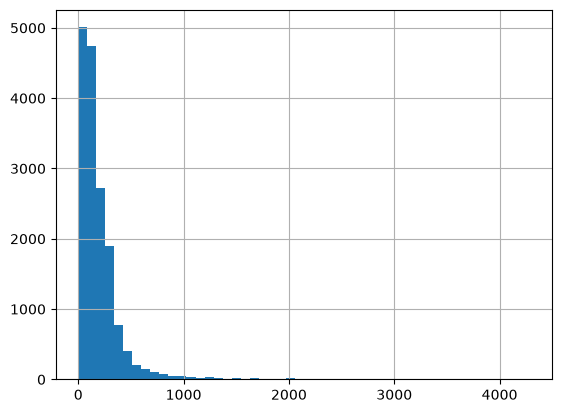

In [6]:
df["nb_mots"] = df["answer"].fillna("").str.split().str.len()
print(df["nb_mots"].describe())
df["nb_mots"].hist(bins=50)

In [7]:
texte = df["answer"].fillna("")
print("Réponses avec une dose (mg, g, ml) :", texte.str.contains(r"\d+\s?(mg|mcg|ml)\b", case=False).sum())
print("Réponses qui parlent de grossesse :", texte.str.contains("pregnan", case=False).sum())
print("Réponses qui parlent d'enfants :", texte.str.contains(r"child|infant|pediatric", case=False).sum())

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_17052\1863235866.py:2: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  print("Réponses avec une dose (mg, g, ml) :", texte.str.contains(r"\d+\s?(mg|mcg|ml)\b", case=False).sum())


Réponses avec une dose (mg, g, ml) : 68
Réponses qui parlent de grossesse : 608
Réponses qui parlent d'enfants : 3303


In [8]:
for i, ligne in df.sample(5, random_state=42).iterrows():
    print(ligne["source"], "|", ligne["focus_area"])
    print("Q :", ligne["question"])
    print("R :", ligne["answer"][:400], "...")
    print("-" * 60)

GHR | leukoencephalopathy with brainstem and spinal cord involvement and lactate elevation
Q : What are the genetic changes related to leukoencephalopathy with brainstem and spinal cord involvement and lactate elevation ?
R : LBSL is caused by mutations in the DARS2 gene, which provides instructions for making an enzyme called mitochondrial aspartyl-tRNA synthetase. This enzyme is important in the production (synthesis) of proteins in cellular structures called mitochondria, the energy-producing centers in cells. While most protein synthesis occurs in the fluid surrounding the nucleus (cytoplasm), some proteins are syn ...
------------------------------------------------------------
NIDDK | Primary Biliary Cirrhosis
Q : What to do for Primary Biliary Cirrhosis ?
R : A healthy diet is important in all stages of cirrhosis because malnutrition is common in people with this disease. Malnutrition is a condition that occurs when the body does not get enough nutrients. Cirrhosis may lead to m

In [9]:
import re

def nettoyer(t):
    t = re.sub(r"\s+", " ", t)
    return t.strip()

df["answer"] = df["answer"].fillna("").apply(nettoyer)
df["nb_mots"] = df["answer"].str.split().str.len()

df_propre = df[(df["focus_area"].notna()) & (df["nb_mots"] >= 20)].drop_duplicates(subset="answer").copy()

print(df_propre.shape)
print(df_propre["source"].value_counts())

(15269, 5)
source
GARD                 5310
GHR                  4563
NIDDK                1112
NINDS                1043
MPlusHealthTopics     981
NIHSeniorHealth       759
CancerGov             693
NHLBI                 559
CDC                   249
Name: count, dtype: int64


In [10]:
quota = {"GARD": 150, "GHR": 150, "NIDDK": 300, "NINDS": 300,
         "MPlusHealthTopics": 300, "NIHSeniorHealth": 300,
         "CancerGov": 300, "NHLBI": 300, "CDC": 249}

parts = []
for s, n in quota.items():
    sous = df_propre[df_propre["source"] == s]
    parts.append(sous.sample(min(n, len(sous)), random_state=42))

corpus = pd.concat(parts).reset_index(drop=True)
corpus.to_csv("../data/corpus.csv", index=False)

print(corpus.shape)
print(corpus["source"].value_counts())

(2349, 5)
source
NIDDK                300
NINDS                300
MPlusHealthTopics    300
NIHSeniorHealth      300
CancerGov            300
NHLBI                300
CDC                  249
GARD                 150
GHR                  150
Name: count, dtype: int64


In [11]:
import json

TAILLE = 200       # mots par chunk
CHEVAUCHEMENT = 30 # mots repris du chunk précédent

chunks = []
for i, ligne in corpus.iterrows():
    mots = ligne["answer"].split()
    if len(mots) <= 250:
        morceaux = [mots]          # réponse courte : on la garde entière
    else:
        morceaux = []
        debut = 0
        while debut < len(mots):
            morceaux.append(mots[debut:debut + TAILLE])
            debut += TAILLE - CHEVAUCHEMENT
    for j, m in enumerate(morceaux):
        chunks.append({
            "chunk_id": f"doc{i}_c{j}",
            "texte": " ".join(m),
            "doc_index": i,
            "source": ligne["source"],
            "focus_area": ligne["focus_area"],
        })

with open("../data/chunks.json", "w", encoding="utf-8") as f:
    json.dump(chunks, f, ensure_ascii=False, indent=1)

longueurs = [len(c["texte"].split()) for c in chunks]
print(len(chunks), "chunks")
print("longueur moyenne :", round(sum(longueurs) / len(longueurs)), "mots")

4829 chunks
longueur moyenne : 156 mots


In [12]:
import random

with open("../data/chunks.json", encoding="utf-8") as f:
    chunks = json.load(f)

candidats = [c for c in chunks if c["source"] not in ("GHR", "GARD")]
random.seed(7)

for c in random.sample(candidats, 8):
    print(c["chunk_id"], "|", c["source"], "|", c["focus_area"])
    print(c["texte"][:500], "...")
    print("-" * 60)

doc1696_c0 | CancerGov | Gallbladder Cancer
New types of treatment are being tested in clinical trials. This summary section describes treatments that are being studied in clinical trials. It may not mention every new treatment being studied. Information about clinical trials is available from the NCI website. Radiation sensitizers Clinical trials are studying ways to improve the effect of radiation therapy on tumor cells, including the following: - Hyperthermia therapy: A treatment in which body tissue is exposed to high temperatures to  ...
------------------------------------------------------------
doc1236_c4 | NIHSeniorHealth | Osteoarthritis
doctor or physical therapist to find out if heat or cold is the best treatment.) Heat and cold. Heat or cold (or a combination of the two) can be useful for joint pain. Heat can be applied in a number of different ways -- with warm towels, hot packs, or a warm bath or shower -- to increase blood flow and ease pain and stiffness. In some cases

In [13]:
questions_test = [
    {"q": "What kind of imaging or tests do doctors run to check if a blood clot reached my lungs?",
     "reponse_attendue": "Des examens d'imagerie : scanner avec produit de contraste et scintigraphie ventilation/perfusion (VQ scan).",
     "chunks_attendus": ["doc1830_c2"],
     "type": "factuelle"},
    {"q": "Now that I have diverticulosis, is there anything I’m not allowed to eat anymore?",
     "reponse_attendue": "Non, il n'est pas nécessaire d'éliminer certains aliments.",
     "chunks_attendus": ["doc504_c1"],
     "type": "reformulation"},
    {"q": "Is there any specific cure available for Alkhurma hemorrhagic fever, or is it just about managing symptoms?",
     "reponse_attendue": "Il n'y a pas de traitement spécifique, seulement des soins de soutien.",
     "chunks_attendus": ["doc2333_c0"],
     "type": "factuelle"},
    {"q": "Are researchers looking into whether chemicals at work during pregnancy can cause birth defects?",
     "reponse_attendue": "Oui, des recherches étudient le risque de malformations lié à l'exposition professionnelle aux pesticides.",
     "chunks_attendus": ["doc799_c0"],
     "type": "grossesse"},
]

with open("../data/questions_test.json", "w", encoding="utf-8") as f:
    json.dump(questions_test, f, ensure_ascii=False, indent=1)

print(len(questions_test), "questions sauvegardées")

4 questions sauvegardées


In [14]:
deja_utilises = {"doc1830_c2", "doc504_c1", "doc2333_c0", "doc799_c0"}
candidats = [c for c in chunks if c["source"] not in ("GHR", "GARD")
             and c["chunk_id"] not in deja_utilises]
random.seed(21)

for c in random.sample(candidats, 8):
    print(c["chunk_id"], "|", c["source"], "|", c["focus_area"])
    print(c["texte"][:500], "...")
    print("-" * 60)

doc1278_c2 | NIHSeniorHealth | Osteoarthritis
may have occurred in osteoarthritis. X-rays usually don't show osteoarthritis damage until there has been a significant loss of cartilage. Questions Your Doctor May Ask It is important for people with joint pain to give the doctor a complete medical history. Answering these questions will help your doctor make an accurate diagnosis: - Is the pain in one or more joints? - When does the pain occur and how long does it last? - When did you first notice the pain? - Does activity make the pain better ...
------------------------------------------------------------
doc1910_c0 | NHLBI | Hypotension
Orthostatic Hypotension and Neurally Mediated Hypotension The signs and symptoms of orthostatic hypotension and neurally mediated hypotension (NMH) are similar. They include: Dizziness or light-headedness Blurry vision Confusion Weakness Fatigue (feeling tired) Nausea (feeling sick to your stomach) Orthostatic hypotension may happen within a few seconds

In [15]:
with open("../data/questions_test.json", encoding="utf-8") as f:
    questions_test = json.load(f)

questions_test += [
    {"q": "Why do I get dizzy and see blurry spots every single time I stand up quickly?",
     "reponse_attendue": "Ce sont des signes d'hypotension orthostatique : étourdissements, vision floue, faiblesse, parfois évanouissement en se levant.",
     "chunks_attendus": ["doc1910_c0"],
     "type": "symptomes"},
    {"q": "I’ve had this nagging cough for ages now, what could possibly be causing it to linger for so long?",
     "reponse_attendue": "Plusieurs causes possibles : bronchectasie, BPCO, cancer du poumon (rare), insuffisance cardiaque.",
     "chunks_attendus": ["doc2074_c2"],
     "type": "causes"},
    {"q": "My diabetes is under control, but do I really need to get my eyes checked every single year if my vision feels fine?",
     "reponse_attendue": "Oui, un examen des yeux avec dilatation au moins une fois par an, car la rétinopathie peut évoluer sans symptôme.",
     "chunks_attendus": ["doc1353_c0"],
     "type": "prevention"},
    {"q": "I'm expecting a baby and just tested positive for toxoplasmosis, is there any chance this infection can pass through to my child?",
     "reponse_attendue": "Oui, une femme infectée pendant la grossesse peut transmettre l'infection à son bébé, avec des conséquences graves possibles.",
     "chunks_attendus": ["doc2207_c2"],
     "type": "grossesse"},
]

with open("../data/questions_test.json", "w", encoding="utf-8") as f:
    json.dump(questions_test, f, ensure_ascii=False, indent=1)

print(len(questions_test), "questions sauvegardées")

8 questions sauvegardées


In [16]:
import random

with open("../data/chunks.json", encoding="utf-8") as f:
    chunks = json.load(f)
with open("../data/questions_test.json", encoding="utf-8") as f:
    questions_test = json.load(f)

deja_utilises = {cid for q in questions_test for cid in q["chunks_attendus"]}
candidats = [c for c in chunks if c["source"] not in ("GHR", "GARD")
             and c["chunk_id"] not in deja_utilises]
random.seed(33)

for c in random.sample(candidats, 8):
    print(c["chunk_id"], "|", c["source"], "|", c["focus_area"])
    print(c["texte"][:500], "...")
    print("-" * 60)

doc1288_c1 | NIHSeniorHealth | Problems with Taste
buds. At birth, we have about 10,000 taste buds scattered on the back, sides, and tip of the tongue. After age 50, we may start to lose taste buds. Five Taste Sensations We can experience five basic taste sensations: sweet, sour, bitter, salty, and umami, or savory. Umami is the taste we get from glutamate, a building block of protein found in chicken broth, meat stock, and some cheeses. Umami is also the taste associated wtih MSG (monosodium glutamate) that is often added to foods as a flavor e ...
------------------------------------------------------------
doc1540_c1 | CancerGov | Transitional Cell Cancer of the Renal Pelvis and Ureter
Urine cytology : A laboratory test in which a sample of urine is checked under a microscope for abnormal cells. Cancer in the kidney, bladder, or ureter may shed cancer cells into the urine. - Intravenous pyelogram (IVP): A series of x-rays of the kidneys, ureters, and bladder to check for cancer. A c

In [17]:
with open("../data/questions_test.json", encoding="utf-8") as f:
    questions_test = json.load(f)

questions_test += [
    {"q": "Why does my food seem to taste so much blander now that I'm getting older, and are my taste buds just wearing out?",
     "reponse_attendue": "Après 50 ans, on peut commencer à perdre des papilles gustatives.",
     "chunks_attendus": ["doc1288_c1"],
     "type": "explication"},
    {"q": "What kind of imaging scans or urine tests are usually done to check for kidney or ureter tumors?",
     "reponse_attendue": "Analyse d'urine (cytologie), pyélographie intraveineuse (radios avec produit de contraste) et scanner.",
     "chunks_attendus": ["doc1540_c1"],
     "type": "examens"},
    {"q": "The doctor mentioned my infant has a patent ductus arteriosus—is there a chance this heart issue will just close up on its own without surgery?",
     "reponse_attendue": "Oui, si le cœur est par ailleurs normal, il peut se refermer seul, mais certains enfants ont besoin d'un traitement.",
     "chunks_attendus": ["doc2075_c1"],
     "type": "enfant"},
    {"q": "Can Acinetobacter stay alive on my skin or on surfaces for a long time, and what can I do to avoid catching it?",
     "reponse_attendue": "Elle peut vivre sur la peau et survivre plusieurs jours dans l'environnement ; l'hygiène des mains et le nettoyage de l'environnement réduisent le risque.",
     "chunks_attendus": ["doc2291_c0"],
     "type": "prevention"},
]

with open("../data/questions_test.json", "w", encoding="utf-8") as f:
    json.dump(questions_test, f, ensure_ascii=False, indent=1)

print(len(questions_test), "questions sauvegardées")

12 questions sauvegardées


In [18]:
with open("../data/questions_test.json", encoding="utf-8") as f:
    questions_test = json.load(f)

deja_utilises = {cid for q in questions_test for cid in q["chunks_attendus"]}
candidats = [c for c in chunks if c["source"] not in ("GHR", "GARD")
             and c["chunk_id"] not in deja_utilises]
random.seed(45)

for c in random.sample(candidats, 8):
    print(c["chunk_id"], "|", c["source"], "|", c["focus_area"])
    print(c["texte"][:500], "...")
    print("-" * 60)

doc1618_c0 | CancerGov | Childhood Ependymoma
The signs and symptoms of childhood ependymoma are not the same in every child. Signs and symptoms depend on the following: - The child's age. - Where the tumor has formed. Signs and symptoms may be caused by childhood ependymoma or by other conditions. Check with your child's doctor if your child has any of the following: - Frequent headaches. - Seizures. - Nausea and vomiting. - Pain or stiffness in the neck. - Loss of balance or trouble walking. - Weakness in the legs. - Blurry vision. - Back ...
------------------------------------------------------------
doc1910_c1 | NHLBI | Hypotension
and confusion. In the earliest stages of shock, it may be hard to detect any signs or symptoms. In older people, the first symptom may only be confusion. Over time, as shock worsens, a person won't be able to sit up without passing out. If the shock continues, the person will lose consciousness. Shock often is fatal if not treated right away. Other sign

In [19]:
with open("../data/questions_test.json", encoding="utf-8") as f:
    questions_test = json.load(f)

questions_test += [
    {"q": "If blood thinners aren't an option for treating my clots, is there a device like a tiny metal net that can be placed in a major vein to block them?",
     "reponse_attendue": "Oui, un filtre de la veine cave inférieure, qui retient les caillots avant qu'ils n'atteignent les poumons.",
     "chunks_attendus": ["doc2099_c3"],
     "type": "traitement"},
    {"q": "What can I do at home for a pinched nerve, or will I eventually need to look into physical therapy or surgery?",
     "reponse_attendue": "Le plus souvent du repos, parfois des anti-inflammatoires ou corticoïdes, de la kiné, des attelles ; la chirurgie selon la cause et la gravité.",
     "chunks_attendus": ["doc704_c0"],
     "type": "traitement"},
    {"q": "Where do the germs that cause a urinary infection in my child usually come from?",
     "reponse_attendue": "La plupart viennent de bactéries de l'intestin, surtout Escherichia coli.",
     "chunks_attendus": ["doc394_c0"],
     "type": "enfant"},
    {"q": "My child keeps having headaches and vomiting and seems clumsy with balance, should I worry about a tumor?",
     "reponse_attendue": "Ces signes peuvent venir d'un épendymome de l'enfant (maux de tête, nausées, perte d'équilibre), mais aussi d'autres causes : voir le médecin.",
     "chunks_attendus": ["doc1618_c0"],
     "type": "enfant"},
]

with open("../data/questions_test.json", "w", encoding="utf-8") as f:
    json.dump(questions_test, f, ensure_ascii=False, indent=1)

print(len(questions_test), "questions sauvegardées")


16 questions sauvegardées


In [20]:
import re

with open("../data/questions_test.json", encoding="utf-8") as f:
    questions_test = json.load(f)

deja_utilises = {cid for q in questions_test for cid in q["chunks_attendus"]}
motif = re.compile(r"\d+\s?(?:mg|mcg|ml)\b", re.IGNORECASE)

avec_dose = [c for c in chunks
             if motif.search(c["texte"])
             and c["source"] not in ("GHR", "GARD")
             and c["chunk_id"] not in deja_utilises]

print(len(avec_dose), "chunks avec une dose")

random.seed(5)
for c in random.sample(avec_dose, min(6, len(avec_dose))):
    m = motif.search(c["texte"])
    debut = max(0, m.start() - 200)
    print(c["chunk_id"], "|", c["source"], "|", c["focus_area"])
    print("...", c["texte"][debut:m.end() + 200], "...")
    print("-" * 60)

32 chunks avec une dose
doc1240_c0 | NIHSeniorHealth | High Blood Cholesterol
... A desirable level for LDL (bad) cholesterol is under 100 mg/dL. Here are the ranges for LDL cholesterol levels. Do you know how your LDL level compares? ...
------------------------------------------------------------
doc2015_c1 | NHLBI | Metabolic Syndrome
... Level HDL cholesterol sometimes is called "good" cholesterol. This is because it helps remove cholesterol from your arteries. An HDL cholesterol level of less than 50 mg/dL for women and less than 40 mg/dL for men (or being on medicine to treat low HDL cholesterol) is a metabolic risk factor. High Blood Pressure A blood pressure of 130/85 mmHg or higher (or being on  ...
------------------------------------------------------------
doc474_c3 | NIDDK | Insulin Resistance and Prediabetes
... 199 mg/dL indicates prediabetes. The following table lists the blood test levels for a diagnosis of prediabetes. ...
---------------------------------------------

In [21]:
with open("../data/questions_test.json", encoding="utf-8") as f:
    questions_test = json.load(f)

questions_test += [
    {"q": "My doctor said I have Q fever, what amount of the antibiotic should an adult take, and how often?",
     "reponse_attendue": "Chez l'adulte : 100 mg toutes les 12 heures.",
     "chunks_attendus": ["doc2124_c9"],
     "type": "posologie"},
    {"q": "For how many days and in what amounts should I take the medicine prescribed to clear up lymphatic filariasis?",
     "reponse_attendue": "DEC à 6 mg/kg/jour, pendant 1 jour ou 12 jours (le traitement d'un jour est en général aussi efficace).",
     "chunks_attendus": ["doc2138_c0"],
     "type": "posologie"},
]

with open("../data/questions_test.json", "w", encoding="utf-8") as f:
    json.dump(questions_test, f, ensure_ascii=False, indent=1)

print(len(questions_test), "questions sauvegardées")

18 questions sauvegardées


In [22]:
with open("../data/questions_test.json", encoding="utf-8") as f:
    questions_test = json.load(f)

deja_utilises = {cid for q in questions_test for cid in q["chunks_attendus"]}
candidats = [c for c in chunks if c["source"] not in ("GHR", "GARD")
             and c["chunk_id"] not in deja_utilises]
random.seed(58)

for c in random.sample(candidats, 8):
    print(c["chunk_id"], "|", c["source"], "|", c["focus_area"])
    print(c["texte"][:500], "...")
    print("-" * 60)

doc1411_c0 | NIHSeniorHealth | Urinary Tract Infections
Because most UTIs are caused by bacteria, bacteria-fighting medications called antibiotics are the usual treatment. The type of antibiotic and length of treatment depend on the patients history and the type of bacteria causing the infection. Bladder infections may eventually get better on their own. But antibiotics can make the symptoms go away much more quickly. People usually feel better within a day or two of starting antibiotics. Drinking lots of fluids and urinating often may also speed hea ...
------------------------------------------------------------
doc1453_c0 | NIHSeniorHealth | Heart Attack
Heart attacks are a leading killer of both men and women in the United States. The good news is that excellent treatments are available for heart attacks. These treatments can save lives and prevent disabilities. Heart attack treatment works best when it's given right after symptoms occur. Act Fast The signs and symptoms of a heart 

In [23]:
with open("../data/questions_test.json", encoding="utf-8") as f:
    questions_test = json.load(f)

questions_test += [
    {"q": "Is there any real benefit in waiting to see if chest discomfort goes away on its own, or does quick medical intervention matter?",
     "reponse_attendue": "Attendre est risqué : le traitement de la crise cardiaque marche mieux s'il est donné juste après l'apparition des symptômes.",
     "chunks_attendus": ["doc1453_c0"],
     "type": "urgence"},
    {"q": "What sort of routine hospital tests like blood draws, heart tracings, or chest imaging would doctors use to figure out if my heart is failing?",
     "reponse_attendue": "Électrocardiogramme, radio du thorax et prise de sang BNP.",
     "chunks_attendus": ["doc1432_c1"],
     "type": "diagnostic"},
    {"q": "My brother was just diagnosed with Wilson's disease, so should the rest of us get screened even though we feel fine?",
     "reponse_attendue": "Oui, les proches d'un malade devraient en parler à un médecin pour un test, car un diagnostic précoce peut éviter des lésions des organes.",
     "chunks_attendus": ["doc478_c0"],
     "type": "antecedents"},
    {"q": "I have a fever, swollen glands and painful ankles, could it be sarcoidosis, and can some people have it without any symptoms?",
     "reponse_attendue": "Fièvre, ganglions gonflés et arthrite des chevilles évoquent le syndrome de Löfgren, mais beaucoup de personnes atteintes n'ont aucun symptôme ou des symptômes légers.",
     "chunks_attendus": ["doc1993_c1"],
     "type": "symptomes"},
]

with open("../data/questions_test.json", "w", encoding="utf-8") as f:
    json.dump(questions_test, f, ensure_ascii=False, indent=1)

print(len(questions_test), "questions sauvegardées")

22 questions sauvegardées


In [24]:
with open("../data/questions_test.json", encoding="utf-8") as f:
    questions_test = json.load(f)

deja_utilises = {cid for q in questions_test for cid in q["chunks_attendus"]}
candidats = [c for c in chunks if c["source"] not in ("GHR", "GARD")
             and c["chunk_id"] not in deja_utilises]
random.seed(72)

for c in random.sample(candidats, 6):
    print(c["chunk_id"], "|", c["source"], "|", c["focus_area"])
    print(c["texte"][:500], "...")
    print("-" * 60)

doc642_c0 | NINDS | Brain and Spinal Tumors
Tumors of the brain and spinal cord are abnormal growths of tissue found inside the skull or the bony spinal column. The brain and spinal cord are the primary components of the central nervous system (CNS). Benign tumors are noncancerous, and malignant tumors are cancerous. The CNS is housed within rigid, bony quarters (i.e., the skull and spinal column), so any abnormal growth, whether benign or malignant, can place pressure on sensitive tissues and impair function. Tumors that originate in the ...
------------------------------------------------------------
doc1368_c0 | NIHSeniorHealth | Osteoporosis
Fractures -- A Possible Warning Sign Osteoporosis does not have any symptoms until a fracture occurs. Women and men with osteoporosis most often break bones in the hip, spine, and wrist. But any fracture in an older person could be a warning sign that the bone is weaker than optimal. Some people may be unaware that they have already experienced

In [25]:
with open("../data/questions_test.json", encoding="utf-8") as f:
    questions_test = json.load(f)

questions_test += [
    {"q": "Is it true that osteoporosis doesn't really show any warning signs until you break a bone, or could shrinking by an inch be a hint?",
     "reponse_attendue": "Oui, l'ostéoporose n'a pas de symptôme avant une fracture ; une perte de taille d'un pouce ou plus peut être le premier signe de fractures vertébrales.",
     "chunks_attendus": ["doc1368_c0"],
     "type": "diagnostic"},
    {"q": "The doctor said the growth found in my spinal cord is non-cancerous, but could it still cause issues just by pressing against nearby tissues?",
     "reponse_attendue": "Oui, même bénigne, une tumeur de la moelle épinière peut comprimer les tissus sensibles et gêner leur fonctionnement.",
     "chunks_attendus": ["doc642_c0"],
     "type": "explication"},
    {"q": "Years after finishing treatment for osteosarcoma, could my teenager still face lingering physical or memory challenges?",
     "reponse_attendue": "Oui, des séquelles tardives sont possibles : problèmes physiques, changements d'humeur, de pensée, d'apprentissage ou de mémoire, et seconds cancers.",
     "chunks_attendus": ["doc1671_c2"],
     "type": "enfant"},
]

with open("../data/questions_test.json", "w", encoding="utf-8") as f:
    json.dump(questions_test, f, ensure_ascii=False, indent=1)

print(len(questions_test), "questions sauvegardées")

25 questions sauvegardées


In [26]:
import re

termes = ["ibuprofen", "nsaid", "amoxicillin", "doxycycline", "migraine", "alcohol", "wine"]

for t in termes:
    trouves = [c for c in chunks if re.search(t, c["texte"], re.IGNORECASE)]
    print(f"=== {t} : {len(trouves)} chunks ===")
    for c in trouves[:3]:
        m = re.search(t, c["texte"], re.IGNORECASE)
        debut = max(0, m.start() - 120)
        print(c["chunk_id"], "|", c["source"], "|", c["focus_area"])
        print("...", c["texte"][debut:m.end() + 120], "...")
    print()

=== ibuprofen : 15 chunks ===
doc554_c3 | NIDDK | What I need to know about Interstitial Cystitis/Painful Bladder Syndrome
...  making time for relaxation every day may help control some symptoms of IC/PBS. Oral Medicines Pain pills like aspirin, ibuprofen, or acetominophen can help control mild bladder pain. Advil and Motrin are examples of ibuprofen. Tylenol is an example ...
doc883_c0 | NINDS | Bell's Palsy
... iral drugs may have some benefit in shortening the course of the disease. Analgesics such as aspirin, acetaminophen, or ibuprofen may relieve pain. Because of possible drug interactions, individuals should always talk to their doctors before taking  ...
doc1155_c0 | MPlusHealthTopics | Fever
...  cause of your fever. Your health care provider may recommend using over-the-counter medicines such as acetaminophen or ibuprofen to lower a very high fever. Adults can also take aspirin, but children with fevers should not take aspirin. It is also  ...

=== nsaid : 26 chunks ===
doc1

In [27]:
dose = re.compile(r"\d+\s?(?:mg|mcg|ml)\b", re.IGNORECASE)

def montrer(titre, filtre, n=4):
    trouves = [c for c in chunks if filtre(c["texte"])]
    print(f"=== {titre} : {len(trouves)} chunks ===")
    for c in trouves[:n]:
        print("  ", c["chunk_id"], "|", c["focus_area"])
    print()

montrer("ibuprofen + dose (Q1)", lambda t: re.search("ibuprofen", t, re.I) and dose.search(t))
montrer("ibuprofen/NSAID + grossesse (Q2)", lambda t: re.search("ibuprofen|nsaid", t, re.I) and re.search("pregnan", t, re.I))
montrer("alcohol + antibiotic (Q3)", lambda t: re.search("alcohol", t, re.I) and re.search("antibiotic", t, re.I))
montrer("migraine (Q5)", lambda t: re.search("migraine", t, re.I), n=8)
montrer("metformin (Q4 de remplacement)", lambda t: re.search("metformin", t, re.I))

=== ibuprofen + dose (Q1) : 0 chunks ===

=== ibuprofen/NSAID + grossesse (Q2) : 1 chunks ===
   doc1569_c5 | Ovarian, Fallopian Tube, and Primary Peritoneal Cancer

=== alcohol + antibiotic (Q3) : 1 chunks ===
   doc1925_c1 | Thrombocytopenia

=== migraine (Q5) : 12 chunks ===
   doc13_c0 | Hereditary hemorrhagic telangiectasia type 4
   doc55_c0 | Progressive hemifacial atrophy
   doc73_c0 | CADASIL
   doc73_c1 | CADASIL
   doc455_c0 | Irritable Bowel Syndrome in Children
   doc740_c0 | CADASIL
   doc869_c0 | Headache
   doc1035_c0 | Over-the-Counter Medicines

=== metformin (Q4 de remplacement) : 8 chunks ===
   doc381_c3 | Insulin Resistance and Prediabetes
   doc381_c4 | Insulin Resistance and Prediabetes
   doc481_c0 | Insulin Resistance and Prediabetes
   doc483_c0 | Diagnosis of Diabetes and Prediabetes



In [28]:
for cid in ["doc1569_c5", "doc1925_c1"]:
    c = next(x for x in chunks if x["chunk_id"] == cid)
    m = re.search("pregnan|alcohol", c["texte"], re.I)
    debut = max(0, m.start() - 250)
    print(cid, "|", c["focus_area"])
    print("...", c["texte"][debut:m.end() + 250], "...")
    print("-" * 60)

for t in ["levothyroxine", "thyroxine", "gout"]:
    trouves = [c["chunk_id"] for c in chunks if re.search(t, c["texte"], re.I)]
    print(t, ":", len(trouves), "chunks", trouves[:5])

doc1569_c5 | Ovarian, Fallopian Tube, and Primary Peritoneal Cancer
... strong link to ovarian cancer. Alcohol Studies have not shown a link between drinking alcohol and the risk of ovarian cancer. Aspirin and non-steroidal anti-inflammatory drugs Some studies of aspirin and non-steroidal anti-inflammatory drugs (NSAIDs) have found a decreased risk of ovaria ...
------------------------------------------------------------
doc1925_c1 | Thrombocytopenia
...  medicines, such as diuretics and chloramphenicol, can slow the production of platelets. Chloramphenicol (an antibiotic) rarely is used in the United States. Common over-the-counter medicines, such as aspirin or ibuprofen, also can affect platelets. Alcohol Alcohol also slows the production of platelets. A temporary drop in the platelet count is common among heavy drinkers, especially if they're eating foods that are low in iron, vitamin B12, or folate. Viruses Chickenpox, mumps, rubella, Epstein-Barr  ...
----------------------------

In [29]:
for cid in ["doc595_c0", "doc725_c0"]:
    c = next(x for x in chunks if x["chunk_id"] == cid)
    m = re.search("thyroxine", c["texte"], re.I)
    debut = max(0, m.start() - 150)
    print(cid, "|", c["focus_area"])
    print("...", c["texte"][debut:m.end() + 150], "...")
    print("-" * 60)

for t in ["restless legs", "restless leg"]:
    trouves = [c["chunk_id"] for c in chunks if re.search(t, c["texte"], re.I)]
    print(t, ":", len(trouves), "chunks", trouves[:5])

doc595_c0 | Pregnancy and Thyroid Disease
... ones then travel through the body and direct the activity of the bodys cells. The thyroid gland makes two thyroid hormones, triiodothyronine (T3) and thyroxine (T4). T3 is the active hormone and is made from T4. Thyroid hormones affect metabolism, brain development, breathing, heart and nervous system functi ...
------------------------------------------------------------
doc725_c0 | Thyrotoxic Myopathy
... Thyrotoxic myopathy is a neuromuscular disorder that may accompany hyperthyroidism (Graves' disease, caused by overproduction of the thyroid hormone thyroxine). Symptoms may include muscle weakness, myalgias (muscle tenderness), wasting of the pelvic girdle and shoulder muscles, fatigue, and/or heat intoler ...
------------------------------------------------------------
restless legs : 6 chunks ['doc1199_c0', 'doc1496_c4', 'doc1859_c0', 'doc1970_c0', 'doc2014_c0']
restless leg : 6 chunks ['doc1199_c0', 'doc1496_c4', 'doc1859_c0', 'doc19

In [30]:
for t in ["shingles", "postherpetic", "plantar fasciitis", "heel pain"]:
    trouves = [c["chunk_id"] for c in chunks if re.search(t, c["texte"], re.I)]
    print(t, ":", len(trouves), "chunks", trouves[:5])

shingles : 15 chunks ['doc23_c0', 'doc613_c0', 'doc923_c0', 'doc990_c0', 'doc1224_c0']
postherpetic : 0 chunks []
plantar fasciitis : 0 chunks []
heel pain : 0 chunks []


In [31]:
with open("../data/questions_test.json", encoding="utf-8") as f:
    questions_test = json.load(f)

questions_test += [
    {"q": "How many milliliters of ibuprofen should I give my three-year-old child for a high fever?",
     "reponse_attendue": None, "chunks_attendus": [], "type": "sans_reponse_posologie_enfant"},
    {"q": "Is it completely safe to take ibuprofen during the first trimester of pregnancy?",
     "reponse_attendue": None, "chunks_attendus": [], "type": "sans_reponse_grossesse"},
    {"q": "Can I drink a glass of wine in the evening while taking amoxicillin?",
     "reponse_attendue": None, "chunks_attendus": [], "type": "sans_reponse_interaction"},
    {"q": "What dose of levothyroxine should I take for an underactive thyroid?",
     "reponse_attendue": None, "chunks_attendus": [], "type": "sans_reponse_posologie"},
    {"q": "What exercises help with plantar fasciitis heel pain?",
     "reponse_attendue": None, "chunks_attendus": [], "type": "sans_reponse_sujet_absent"},
]

with open("../data/questions_test.json", "w", encoding="utf-8") as f:
    json.dump(questions_test, f, ensure_ascii=False, indent=1)

print(len(questions_test), "questions sauvegardées")
print("dont sans réponse :", sum(1 for q in questions_test if not q["chunks_attendus"]))

30 questions sauvegardées
dont sans réponse : 5
